module://matplotlib_inline.backend_inline
Image 1 shape: (320, 400, 3)
Image 2 shape: (320, 400, 3)
Points shape: (5, 2)


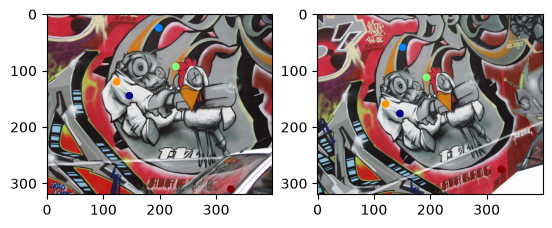

In [5]:
import cv2, numpy as np, random
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib

print(matplotlib.get_backend())

category = "v_bird"
image1_path = f"Data/graf/img1.ppm"
image2_path = f"Data/graf/img2.ppm"
H12_path = f"Data/graf/H1to2p.txt"

# read images and homography matrix
image1 = cv2.imread(image1_path, 1) # 0: grayscale | 1: bgr
image2 = cv2.imread(image2_path, 1) # 0: grayscale | 1: bgr
H = np.loadtxt(H12_path)

# Check image shape
print("Image 1 shape:", image1.shape)
print("Image 2 shape:", image2.shape)

h1, w1 = image1.shape[:2]
h2, w2 = image2.shape[:2]

# generate random points
num_points = 5
np.random.seed(58) #reproducibility
pts = np.random.rand(num_points, 2,) * np.array([w1,h1])
print("Points shape:", pts.shape)

# Project transformation
pts = np.hstack([pts, np.ones((num_points,1))]) # [x,y,1]
pts_t = (H @ pts.T).T
pts_t = pts_t[:, :2] / pts_t[:, 2:3]

# Plot Figures
fig, ax = plt.subplots(1,2)
colors = cm.jet(np.linspace(0,1, len(pts)))
ax[0].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
ax[0].scatter(pts[:,0], pts[:,1], s=20, c=colors)
ax[1].imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
ax[1].scatter(pts_t[:,0], pts_t[:,1], s=20, c=colors)
plt.show()

In [6]:
sift= cv2.SIFT_create()

kpts1, dscp1 = sift.detectAndCompute(image1, None)

# Lista de keypoints
print(kpts1[0].pt)
print(kpts1[0].size)

#dsc array
print(dscp1.shape)

kpts2, dscp2 = sift.detectAndCompute(image2, None)

# Lista de keypoints
print(kpts2[0].pt)
print(kpts2[0].size)

#dsc array
print(dscp2.shape)

matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
matches = matcher.match(dscp1, dscp2)



(2.2717018127441406, 277.8520812988281)
2.219050645828247
(1061, 128)
(2.3770463466644287, 184.5257568359375)
2.0873465538024902
(1243, 128)


In [7]:
matches[0]

< cv2.DMatch 000001BEA6502590>

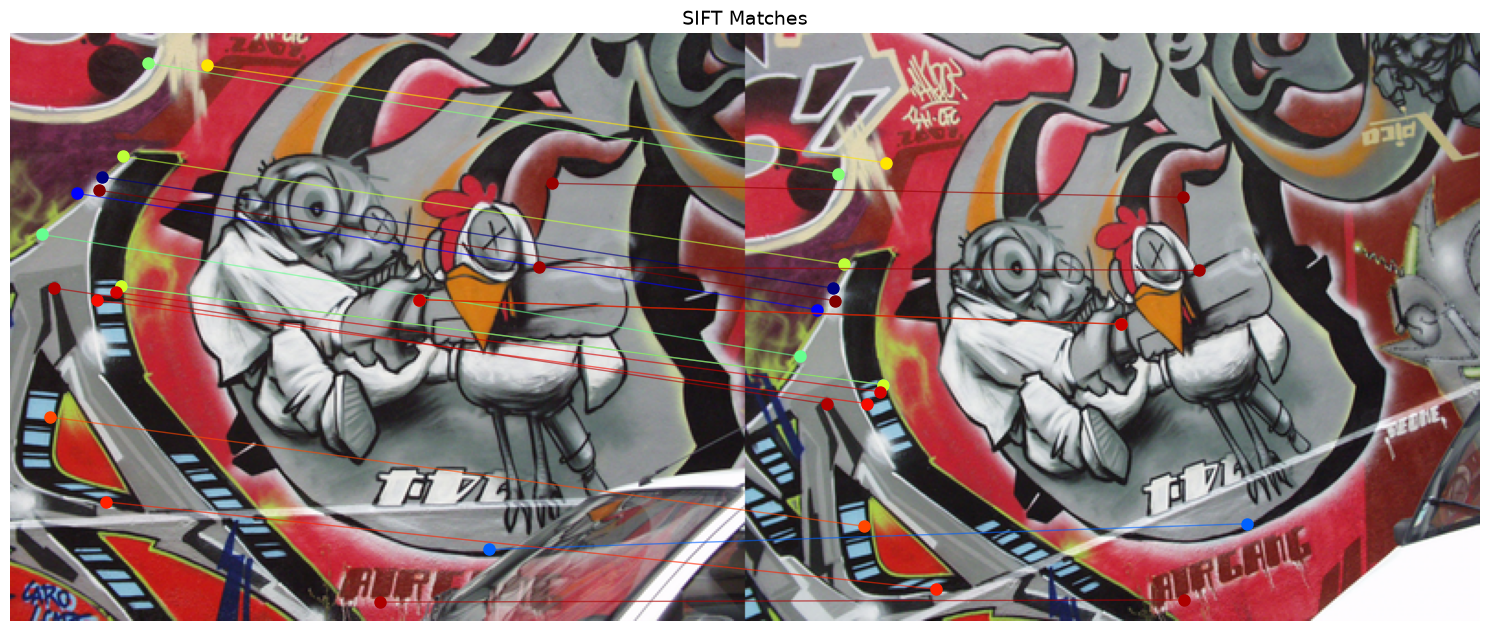


Top 20 matches (ordenados por distância euclidiana):
1. Distance: 32.8177, Query idx: 119, Train idx: 173
2. Distance: 36.8239, Query idx: 95, Train idx: 146
3. Distance: 39.8372, Query idx: 751, Train idx: 896
4. Distance: 41.7493, Query idx: 143, Train idx: 255
5. Distance: 47.7808, Query idx: 39, Train idx: 122
6. Distance: 48.9898, Query idx: 180, Train idx: 182
7. Distance: 51.2055, Query idx: 145, Train idx: 196
8. Distance: 51.8652, Query idx: 142, Train idx: 256
9. Distance: 53.8702, Query idx: 234, Train idx: 260
10. Distance: 58.1979, Query idx: 632, Train idx: 695
11. Distance: 59.1523, Query idx: 57, Train idx: 222
12. Distance: 60.4649, Query idx: 124, Train idx: 339
13. Distance: 61.1964, Query idx: 112, Train idx: 229
14. Distance: 62.0081, Query idx: 136, Train idx: 246
15. Distance: 62.3939, Query idx: 631, Train idx: 694
16. Distance: 63.0872, Query idx: 65, Train idx: 162
17. Distance: 63.2218, Query idx: 565, Train idx: 811
18. Distance: 63.5925, Query idx: 852, Tr

In [ ]:
# next step: keypoints de uma imagem para a outra, fazendo a distância euclidiana entre os descritores.

# matches por distância euclidiana (quanto menor, melhor o match)
matches = sorted(matches, key=lambda x: x.distance)

top_n = 20 #posso alterar para outro número
best_matches = matches[:top_n]

# Extract keypoints e distâncias
kpts_img1 = np.array([kpts1[m.queryIdx].pt for m in best_matches])
kpts_img2 = np.array([kpts2[m.trainIdx].pt for m in best_matches])
distances = np.array([m.distance for m in best_matches])

# Normalizar distâncias para cores (0-1)
norm_distances = (distances - distances.min()) / (distances.max() - distances.min())


fig, ax = plt.subplots(figsize=(15, 8))
h1, w1 = image1.shape[:2]
h2, w2 = image2.shape[:2]
max_h = max(h1, h2)
combined_img = np.zeros((max_h, w1 + w2, 3), dtype=np.uint8)
combined_img[:h1, :w1] = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
combined_img[:h2, w1:w1+w2] = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

ax.imshow(combined_img)

# desenho
colors = cm.jet(norm_distances)
for i, (pt1, pt2, dist) in enumerate(zip(kpts_img1, kpts_img2, distances)):
    # Ponto em imagem 1
    ax.plot(pt1[0], pt1[1], 'o', color=colors[i], markersize=8)
    # Ponto em imagem 2 (ajustado para posição na imagem combinada)
    ax.plot(pt2[0] + w1, pt2[1], 'o', color=colors[i], markersize=8)
    # Linha ligando os matches
    ax.plot([pt1[0], pt2[0] + w1], [pt1[1], pt2[1]], '-', color=colors[i], alpha=0.6, linewidth=1)

ax.set_title(f'SIFT Matches', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} matches (ordenados por distância euclidiana):")
for i, m in enumerate(best_matches):
    print(f"{i+1}. Distance: {m.distance:.4f}, Query idx: {m.queryIdx}, Train idx: {m.trainIdx}")

In [ ]:
#: {len(best_matches)} melhores matches (cor = distância euclidiana)

Reprojection errors (keypoints projetados vs matches reais):
  Média: 0.3762 pixels
  Min: 0.0265 pixels
  Max: 1.3955 pixels
  Std: 0.3473 pixels


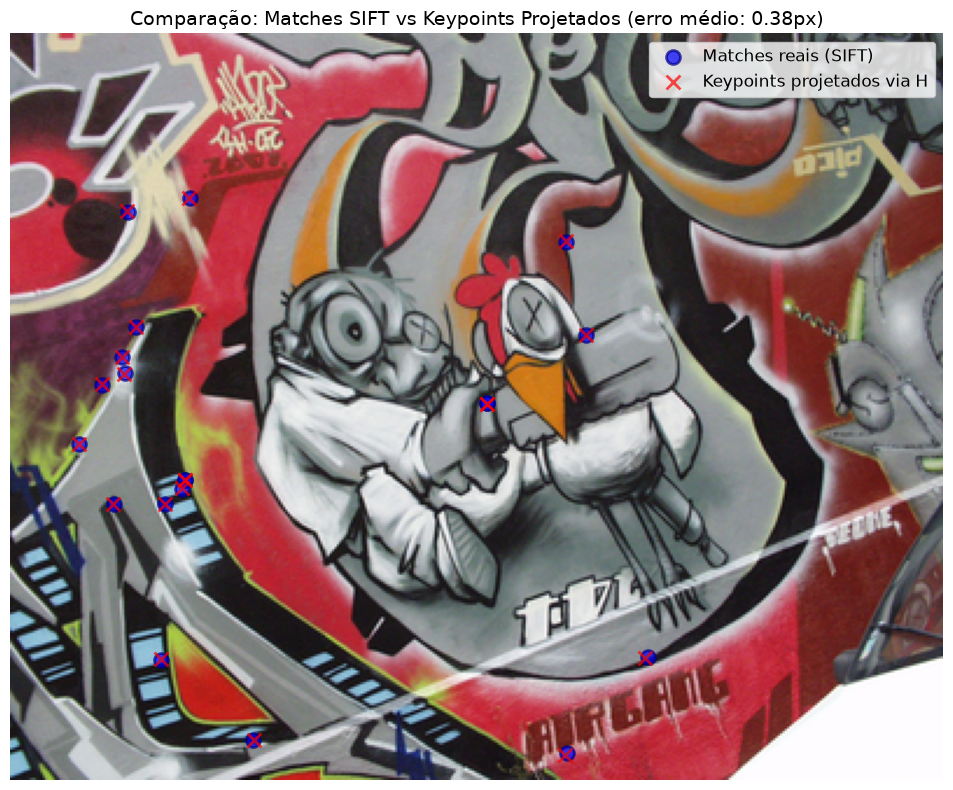


Detalhes por match:
  Match 1: erro = 0.2260 px
  Match 2: erro = 0.3636 px
  Match 3: erro = 1.3955 px
  Match 4: erro = 0.2387 px
  Match 5: erro = 0.2624 px
  Match 6: erro = 0.4938 px
  Match 7: erro = 0.2842 px
  Match 8: erro = 0.2387 px
  Match 9: erro = 0.2756 px
  Match 10: erro = 0.3291 px
  Match 11: erro = 0.2335 px
  Match 12: erro = 0.3182 px
  Match 13: erro = 0.0265 px
  Match 14: erro = 0.2642 px
  Match 15: erro = 0.3291 px
  Match 16: erro = 0.1729 px
  Match 17: erro = 1.3741 px
  Match 18: erro = 0.2870 px
  Match 19: erro = 0.2232 px
  Match 20: erro = 0.1881 px


In [10]:
# Projetar os keypoints da imagem 1 para a imagem 2 usando a homografia H
kpts_img1_homogeneous = np.hstack([kpts_img1, np.ones((len(kpts_img1), 1))])  # Adiciona coordenada homogênea
kpts_img1_projected = (H @ kpts_img1_homogeneous.T).T

# Normalizar coordenadas homogêneas (dividir por z)
kpts_img1_projected = kpts_img1_projected[:, :2] / kpts_img1_projected[:, 2:3]

# Comparar com os keypoints reais em img2 (dos matches)
reprojection_errors = np.linalg.norm(kpts_img1_projected - kpts_img2, axis=1)

print(f"Reprojection errors (keypoints projetados vs matches reais):")
print(f"  Média: {reprojection_errors.mean():.4f} pixels")
print(f"  Min: {reprojection_errors.min():.4f} pixels")
print(f"  Max: {reprojection_errors.max():.4f} pixels")
print(f"  Std: {reprojection_errors.std():.4f} pixels")

# Visualizar: pontos projetados vs matches reais
fig, ax = plt.subplots(figsize=(15, 8))

# Imagem 2
h2, w2 = image2.shape[:2]
ax.imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))

# Desenhar matches reais (kpts_img2) em azul
ax.scatter(kpts_img2[:, 0], kpts_img2[:, 1], s=100, c='blue', marker='o', 
           label='Matches reais (SIFT)', alpha=0.7, edgecolors='darkblue', linewidths=2)

# Desenhar keypoints projetados (kpts_img1_projected) em vermelho
ax.scatter(kpts_img1_projected[:, 0], kpts_img1_projected[:, 1], s=100, c='red', marker='x', 
           label='Keypoints projetados via H', alpha=0.7, linewidths=2)

# Desenhar linhas do erro de reproject
for i in range(len(kpts_img2)):
    ax.plot([kpts_img2[i, 0], kpts_img1_projected[i, 0]], 
            [kpts_img2[i, 1], kpts_img1_projected[i, 1]], 
            'g--', alpha=0.3, linewidth=1)

ax.set_title(f'Comparação: Matches SIFT vs Keypoints Projetados (erro médio: {reprojection_errors.mean():.2f}px)', fontsize=14)
ax.legend(fontsize=12)
ax.axis('off')
plt.tight_layout()
plt.show()

# Tabela de erros
print(f"\nDetalhes por match:")
for i, err in enumerate(reprojection_errors):
    print(f"  Match {i+1}: erro = {err:.4f} px")

In [11]:
# Precision of keypoint matching based on reprojection error
threshold = 5.0  # pixels
num_correct_matches = np.sum(reprojection_errors < threshold)   

